In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import wandb
import csv

# 1. Rank truncation

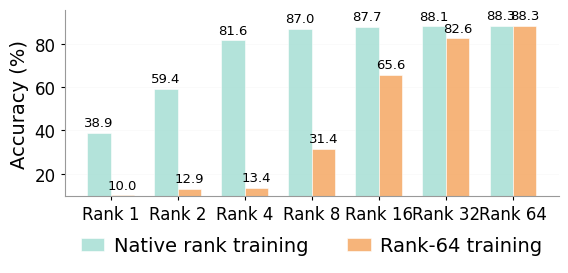

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Load exp_01 results ---
native = pd.read_csv('../results/exp_01/native_rank_results.csv')
truncated = pd.read_csv('../results/exp_01/truncated_rank_results.csv')

# Merge on rank
merged = pd.merge(
    native.rename(columns={'test_acc': 'native_acc'}),
    truncated.rename(columns={'test_acc': 'truncated_acc'}),
    on='rank', how='inner', suffixes=('_native', '_truncated')
).sort_values('rank')

# --- Style ---
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 15,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#666666',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

colors = {
    'primary': '#A0DDD1',
    'secondary': '#F4A259',
    'text': 'black',
    'light_gray': '#E8E8E8',
    'med_gray': '#999999'
}

# --- Plot ---
x = np.arange(len(merged['rank']))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 3))
fig.patch.set_facecolor('white')

bars1 = ax.bar(x - width/2, merged['native_acc'], width,
               color=colors['primary'], alpha=0.8,
               label='Native rank training',
               edgecolor='white', linewidth=0.5)

bars2 = ax.bar(x + width/2, merged['truncated_acc'], width,
               color=colors['secondary'], alpha=0.8,
               label='Rank-64 training',
               edgecolor='white', linewidth=0.5)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(0.8)
    ax.spines[spine].set_color(colors['med_gray'])

ax.grid(axis='y', alpha=0.3, linestyle='-', linewidth=0.5,
        color=colors['light_gray'], zorder=1)
ax.set_axisbelow(True)

ax.set_ylabel('Accuracy (%)', fontsize=14, color=colors['text'], fontweight='500')
ax.set_xticks(x)
ax.set_xticklabels([f'Rank {r}' for r in merged['rank']],
                   fontsize=25, color=colors['text'])

y_min = min(merged['native_acc'].min(), merged['truncated_acc'].min()) * 0.95
y_max = max(merged['native_acc'].max(), merged['truncated_acc'].max()) * 1.08

ax.set_ylim(y_min, y_max)

if y_max <= 1:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}'))
else:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.1f}'))

ax.tick_params(axis='both', labelsize=12, colors=colors['text'])

for i in x:
    native_val = merged['native_acc'].iloc[i]
    truncated_val = merged['truncated_acc'].iloc[i]

    if y_max <= 1:
        native_text = f"{native_val*100:.1f}"
        truncated_text = f"{truncated_val*100:.1f}"
    else:
        native_text = f"{native_val:.2f}"
        truncated_text = f"{truncated_val:.2f}"

    ax.text(i - width/2, native_val + (y_max - y_min) * 0.02, native_text,
            ha='center', va='bottom', fontsize=9.5, color=colors['text'],
            fontweight='300')
    ax.text(i + width/2, truncated_val + (y_max - y_min) * 0.02, truncated_text,
            ha='center', va='bottom', fontsize=9.5, color=colors['text'],
            fontweight='300')

legend = ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
                  ncol=2, frameon=False, fontsize=14,
                  handlelength=1.2, handletextpad=0.5, columnspacing=2)
for text in legend.get_texts():
    text.set_color(colors['text'])

ax.set_facecolor('white')
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
#fig.savefig('../figures/native_training.pdf')
plt.show()

# 2. Nested Subspace Network Example

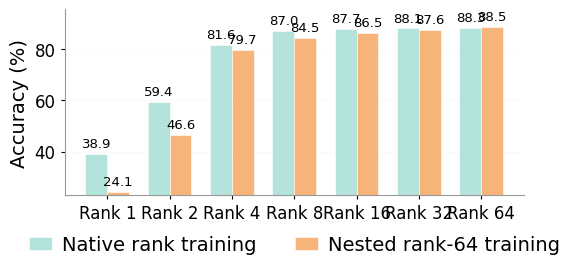

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Load exp_02 results ---
native = pd.read_csv('../results/exp_02/native_rank_results.csv')
nested = pd.read_csv('../results/exp_02/nested_rank_results.csv')

# Merge on rank
merged = pd.merge(
    native.rename(columns={'test_acc': 'native_acc'}),
    nested.rename(columns={'test_acc': 'nested_acc'}),
    on='rank', how='inner', suffixes=('_native', '_nested')
).sort_values('rank')

# --- Style ---
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 15,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#666666',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

colors = {
    'primary': '#A0DDD1',
    'secondary': '#F4A259',
    'text': 'black',
    'light_gray': '#E8E8E8',
    'med_gray': '#999999'
}

# --- Plot ---
x = np.arange(len(merged['rank']))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 3))
fig.patch.set_facecolor('white')

bars1 = ax.bar(x - width/2, merged['native_acc'], width,
               color=colors['primary'], alpha=0.8,
               label='Native rank training',
               edgecolor='white', linewidth=0.5)

bars2 = ax.bar(x + width/2, merged['nested_acc'], width,
               color=colors['secondary'], alpha=0.8,
               label='Nested rank-64 training',
               edgecolor='white', linewidth=0.5)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(0.8)
    ax.spines[spine].set_color(colors['med_gray'])

ax.grid(axis='y', alpha=0.3, linestyle='-', linewidth=0.5,
        color=colors['light_gray'], zorder=1)
ax.set_axisbelow(True)

ax.set_ylabel('Accuracy (%)', fontsize=14, color=colors['text'], fontweight='500')
ax.set_xticks(x)
ax.set_xticklabels([f'Rank {r}' for r in merged['rank']],
                   fontsize=25, color=colors['text'])

y_min = min(merged['native_acc'].min(), merged['nested_acc'].min()) * 0.95
y_max = max(merged['native_acc'].max(), merged['nested_acc'].max()) * 1.08

ax.set_ylim(y_min, y_max)

if y_max <= 1:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f}'))
else:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.1f}'))

ax.tick_params(axis='both', labelsize=12, colors=colors['text'])

for i in x:
    native_val = merged['native_acc'].iloc[i]
    nested_val = merged['nested_acc'].iloc[i]

    if y_max <= 1:
        native_text = f"{native_val*100:.1f}"
        nested_text = f"{nested_val*100:.1f}"
    else:
        native_text = f"{native_val:.2f}"
        nested_text = f"{nested_val:.2f}"

    ax.text(i - width/2, native_val + (y_max - y_min) * 0.02, native_text,
            ha='center', va='bottom', fontsize=9.5, color=colors['text'],
            fontweight='300')
    ax.text(i + width/2, nested_val + (y_max - y_min) * 0.02, nested_text,
            ha='center', va='bottom', fontsize=9.5, color=colors['text'],
            fontweight='300')

legend = ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
                  ncol=2, frameon=False, fontsize=14,
                  handlelength=1.2, handletextpad=0.5, columnspacing=2)
for text in legend.get_texts():
    text.set_color(colors['text'])

ax.set_facecolor('white')
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
#fig.savefig('../figures/nested_training.pdf')
plt.show()

# 3. Learned log variances

## 3.1. Results from the paper

In [6]:
import wandb
wandb.login()

api = wandb.Api()

run_path = 'pauliusrauba/low-rank-performance/039zf4qr'
run = api.run(run_path)
history_df = run.history()

ranks_to_track = [1, 2, 4, 8, 16, 32, 64]

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/azureuser/.netrc.
wandb: Currently logged in as: pauliusrauba to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


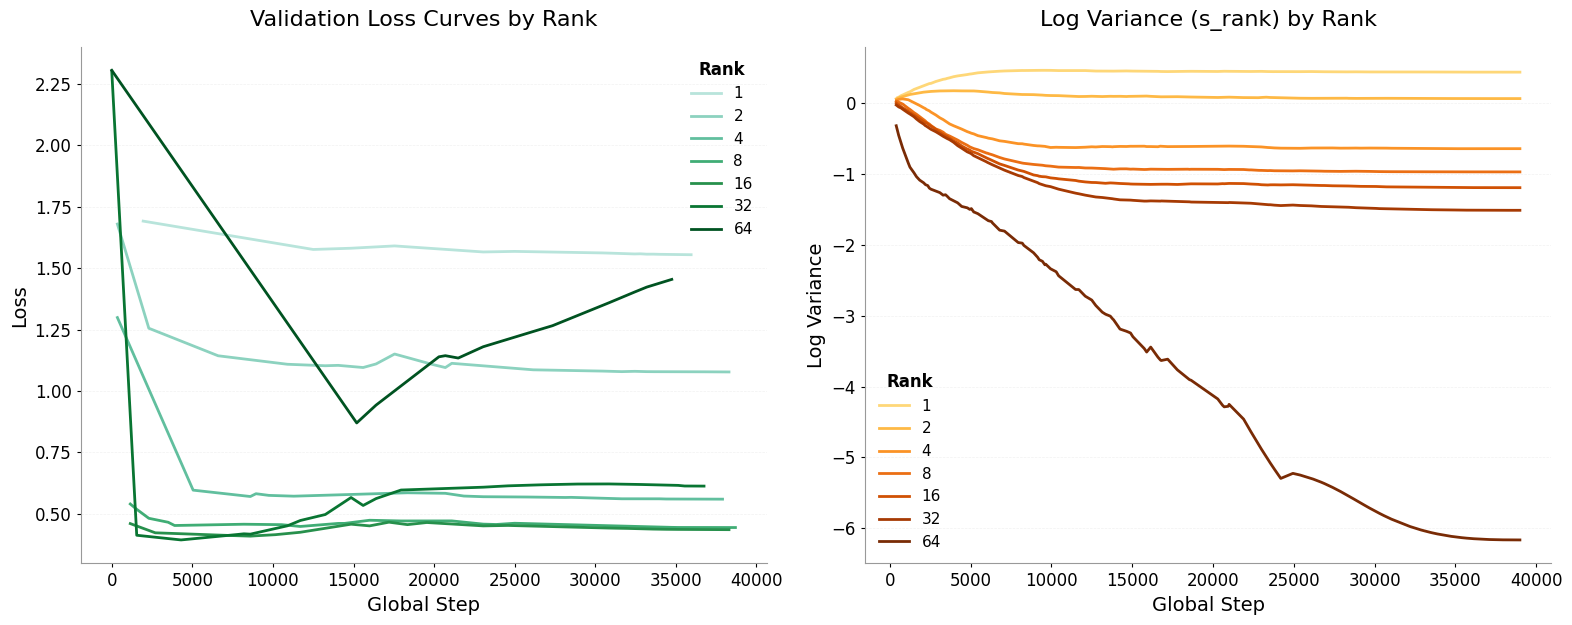

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

# --- Mock DataFrame Generation ---
# In your notebook, you will already have 'history_df' loaded.
# This section is just to make this script runnable for demonstration.
# You can safely comment out or delete this part.
columns = ['trainer/global_step', '_step', '_runtime', 'val/r4_acc', 'epoch', 'val/r4_loss', '_timestamp', 'val/average_ood_rank_accuracy', 'val/average_rank_accuracy', 's_rank_16_step', 's_rank_1_step', 'train/ce_rank_16_step', 'train/ce_rank_32_step', 's_rank_2_step', 'train/ce_rank_2_step', 'train/ce_rank_64_step', 'train/acc_step', 's_rank_64_step', 's_rank_4_step', 'train/ce_rank_4_step', 's_rank_8_step', 's_rank_32_step', 'train/ce_rank_8_step', 'r_variant_step', 'train/ce_rank_1_step', 'train/loss_step', 'r_anchor_step', 'val/r64_acc', 'val/r64_loss', 'val/r16_acc', 'val/r16_loss', 'val/r1_acc', 'val/r1_loss', 'val/acc', 'val/loss', 'val/r32_loss', 'val/r32_acc', 'val/r2_acc', 'val/r2_loss', 'val/r10_acc', 'val/r10_loss', 'lr-AdamW', 'val/r5_acc', 'val/r5_loss', 'val/r20_acc', 'val/r20_loss', 'train/ce_rank_4_epoch', 'r_anchor_epoch', 's_rank_16_epoch', 'train/loss_epoch', 's_rank_8_epoch', 's_rank_32_epoch', 'r_variant_epoch', 'train/acc_epoch', 'train/ce_rank_8_epoch', 'train/ce_rank_32_epoch', 'train/ce_rank_64_epoch', 's_rank_1_epoch', 's_rank_64_epoch', 's_rank_2_epoch', 'train/ce_rank_1_epoch', 's_rank_4_epoch', 'train/ce_rank_2_epoch', 'train/ce_rank_16_epoch', 'val/r3_loss', 'val/r3_acc', 'val/r40_acc', 'val/r40_loss', 'val/r50_loss', 'val/r50_acc', 'val/r30_acc', 'val/r30_loss', 'val/r8_loss', 'val/r8_acc']


# 1. Set Style Parameters
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 15,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#666666',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# Professional color palette from your example
colors = {
    'primary': '#A0DDD1',      # Sea green
    'secondary': '#F4A259',    # Coral
    'text': 'black',           # Dark gray for text
    'light_gray': '#E8E8E8',   # Light gray for grid
    'med_gray': '#999999'      # Medium gray for axes
}

# 2. Prepare Data for Plotting

# Define the specific ranks you want to track
ranks_to_track = [1, 2, 4, 8, 16, 32, 64]

# Filter and sort loss columns based on the specified ranks
loss_cols_to_plot = [f'val/r{r}_loss' for r in ranks_to_track if f'val/r{r}_loss' in history_df.columns]
ranks_for_loss = [r for r in ranks_to_track if f'val/r{r}_loss' in history_df.columns]

# Filter and sort s_rank columns based on the specified ranks
s_rank_cols_to_plot = [f's_rank_{r}_step' for r in ranks_to_track if f's_rank_{r}_step' in history_df.columns]
ranks_for_s = [r for r in ranks_to_track if f's_rank_{r}_step' in history_df.columns]

# 3. Generate Color Gradients
# We use matplotlib's built-in colormaps to create smooth gradients.
primary_cmap = plt.get_cmap('BuGn')
secondary_cmap = plt.get_cmap('YlOrBr')

loss_colors = primary_cmap(np.linspace(0.3, 0.95, len(loss_cols_to_plot)))
s_rank_colors = secondary_cmap(np.linspace(0.3, 0.95, len(s_rank_cols_to_plot)))


# 4. Create the Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
fig.patch.set_facecolor('white')

# --- Plot 1: Validation Loss Curves ---
ax1 = axes[0]
for i, col in enumerate(loss_cols_to_plot):
    rank = ranks_for_loss[i]
    # Drop NaNs for clean plotting, as some steps might not have logs
    plot_df = history_df[['trainer/global_step', col]].dropna()
    ax1.plot(plot_df['trainer/global_step'], plot_df[col],
             color=loss_colors[i], label=f'{rank}', linewidth=2)

# --- Plot 2: Log Variance (s_rank) ---
ax2 = axes[1]
for i, col in enumerate(s_rank_cols_to_plot):
    rank = ranks_for_s[i]
    plot_df = history_df[['trainer/global_step', col]].dropna()
    ax2.plot(plot_df['trainer/global_step'], plot_df[col],
             color=s_rank_colors[i], label=f'{rank}', linewidth=2)


# 5. Apply Professional Styling to Both Plots
for ax in axes:
    # Remove top and right spines for a cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Style the remaining spines
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(0.8)
        ax.spines[spine].set_color(colors['med_gray'])
        
    # Add a light grid for better readability
    ax.grid(axis='y', alpha=0.6, linestyle='--', linewidth=0.5, 
            color=colors['light_gray'], zorder=1)
    ax.set_axisbelow(True)
    
    # Style ticks
    ax.tick_params(axis='both', which='major', labelsize=12, colors=colors['text'])
    
    # Set a white background
    ax.set_facecolor('white')
    
    # Add and style the legend
    legend = ax.legend(title='Rank', fontsize=11, title_fontsize=12)
    legend.get_title().set_fontweight('bold')
    for text in legend.get_texts():
        text.set_color(colors['text'])

# --- Customize Individual Plots ---

# Customize Plot 1
ax1.set_title('Validation Loss Curves by Rank', fontsize=16, color=colors['text'], fontweight='500', pad=15)
ax1.set_xlabel('Global Step', fontsize=14, color=colors['text'])
ax1.set_ylabel('Loss', fontsize=14, color=colors['text'])

# Customize Plot 2
ax2.set_title('Log Variance (s_rank) by Rank', fontsize=16, color=colors['text'], fontweight='500', pad=15)
ax2.set_xlabel('Global Step', fontsize=14, color=colors['text'])
ax2.set_ylabel('Log Variance', fontsize=14, color=colors['text'])

# Adjust layout to prevent titles/labels from overlapping
plt.tight_layout()
plt.show()


# 3.2. Simple reproducible results from standalone experiment

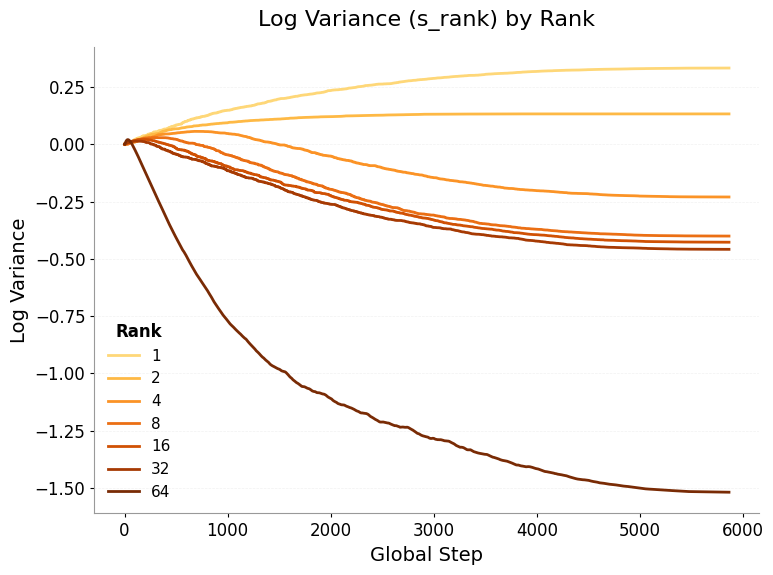

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# --- Load exp_04 results ---
history_df = pd.read_csv('../results/exp_04/log_variance_history.csv')
# 1. Set Style Parameters
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 15,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#666666',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})
colors = {
    'primary': '#A0DDD1',
    'secondary': '#F4A259',
    'text': 'black',
    'light_gray': '#E8E8E8',
    'med_gray': '#999999'
}
# 2. Prepare Data
ranks_to_track = [1, 2, 4, 8, 16, 32, 64]
s_rank_cols_to_plot = [f's_rank_{r}' for r in ranks_to_track if f's_rank_{r}' in history_df.columns]
ranks_for_s = [r for r in ranks_to_track if f's_rank_{r}' in history_df.columns]
# 3. Generate Color Gradient
secondary_cmap = plt.get_cmap('YlOrBr')
s_rank_colors = secondary_cmap(np.linspace(0.3, 0.95, len(s_rank_cols_to_plot)))
# 4. Create the Plot
fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('white')
for i, col in enumerate(s_rank_cols_to_plot):
    rank = ranks_for_s[i]
    plot_df = history_df[['global_step', col]].dropna()
    ax.plot(plot_df['global_step'], plot_df[col],
            color=s_rank_colors[i], label=f'{rank}', linewidth=2)
# 5. Apply Professional Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_linewidth(0.8)
    ax.spines[spine].set_color(colors['med_gray'])
ax.grid(axis='y', alpha=0.6, linestyle='--', linewidth=0.5,
        color=colors['light_gray'], zorder=1)
ax.set_axisbelow(True)
ax.tick_params(axis='both', which='major', labelsize=12, colors=colors['text'])
ax.set_facecolor('white')
legend = ax.legend(title='Rank', fontsize=11, title_fontsize=12)
legend.get_title().set_fontweight('bold')
for text in legend.get_texts():
    text.set_color(colors['text'])
ax.set_title('Log Variance (s_rank) by Rank', fontsize=16, color=colors['text'], fontweight='500', pad=15)
ax.set_xlabel('Global Step', fontsize=14, color=colors['text'])
ax.set_ylabel('Log Variance', fontsize=14, color=colors['text'])
plt.tight_layout()
#fig.savefig('../figures/log_variance_exp04.pdf')
plt.show()


# 4. Ablation results

# 4.1. Results from the paper

In [12]:
# Get the checkpoint that corresponds to the lowest validation loss
import wandb
import pandas as pd

def find_best_checkpoint(model_name, run_name, chkpt_base='/mnt/pdata/pr501/shortcut-models/checkpoints'):
    """Finds best checkpoint for a given run based on validation loss"""
    api = wandb.Api()
    run = api.run(run_name)

    history = run.scan_history(keys=['epoch', 'val/loss'])
    df = pd.DataFrame(history)
    # Get only saved epochs
    saved_epochs = np.arange(9, 109, 10)

    df = df[df.epoch.isin(saved_epochs)].copy()

    # Find epoch with minimum val loss
    best_epoch = df.loc[df['val/loss'].idxmin()]['epoch']

    # checkpoint_path
    checkpoint_path = f'{chkpt_base}/{model_name}-epoch={int(best_epoch):03d}.ckpt'
    return checkpoint_path


In [13]:
runs_to_names = {
    # Baselines
    'CE Only Anchor': ['for-paper-low-rank-teacher-only', 'pauliusrauba/low-rank-performance/pwu2ynn4'],
    'One CE + Hard orthogonality': ['for-paper-low-rank-hard-orthogonality', 'pauliusrauba/low-rank-performance/8gjuyn7e'],

    # Variations
    'Two CEs': ['for-paper-low-rank-ce-no-consistency', 'pauliusrauba/low-rank-performance/2ciim0l9'],
    'Two CEs + Logits Regularization': ['for-paper-low-rank-ce-with-consistency', 'pauliusrauba/low-rank-performance/y0kespia'],
    'Two CEs + Residual orthogonality': ['for-paper-low-rank-ce-with-residual-orthogonality', 'pauliusrauba/low-rank-performance/enjfnffl'],
    'Two CEs + Hidden regularization': ['for-paper-low-rank-ce-with-feature-consistency', 'pauliusrauba/low-rank-performance/czeuga4y'],
} 

run_name = 'pauliusrauba/low-rank-performance/pwu2ynn4'
model_name = 'for-paper-low-rank-ce-with-consistency'

chkpt_paths = {}
# Get checkpoints
for abbrev, info in runs_to_names.items():
    model_name, run_name = info

    ckpt = find_best_checkpoint(model_name, run_name)
    chkpt_paths[abbrev] = ckpt

In [18]:
import pandas as pd
import numpy as np
import wandb
import torch
import torch.nn.functional as F
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Subset

import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..', 'src'))
from lowrank.models.lowrank_mlp_ce import DynamicMLP
from lowrank.data.cifar_emb import CIFAR10EmbeddingDataModule

# --- 1. Configuration ---
api = wandb.Api()

runs_to_names = {
    'CE Only (Anchor)':                 ['for-paper-low-rank-teacher-only',                  'pauliusrauba/low-rank-performance/pwu2ynn4'],
    'One CE + Hard Orthogonality':      ['for-paper-low-rank-hard-orthogonality',            'pauliusrauba/low-rank-performance/8gjuyn7e'],
    'Two CEs':                          ['for-paper-low-rank-ce-no-consistency',              'pauliusrauba/low-rank-performance/2ciim0l9'],
    'Two CEs + Logits Regularization':  ['for-paper-low-rank-ce-with-consistency',            'pauliusrauba/low-rank-performance/y0kespia'],
    'Two CEs + Residual Orthogonality': ['for-paper-low-rank-ce-with-residual-orthogonality', 'pauliusrauba/low-rank-performance/enjfnffl'],
    'Two CEs + Hidden Regularization':  ['for-paper-low-rank-ce-with-feature-consistency',    'pauliusrauba/low-rank-performance/czeuga4y'],
}

IN_D_RANKS = [64, 32, 16, 8, 4, 2]
OOD_RANKS  = [50, 40, 30, 20, 10, 5, 3]
ALL_RANKS  = sorted(set(IN_D_RANKS + OOD_RANKS + [1]), reverse=True)
CHKPT_BASE = '/mnt/pdata/pr501/shortcut-models/checkpoints'
NUM_BOOTSTRAPS = 5
BATCH_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 2. Find best checkpoint per run (lowest val/loss) ---
def find_best_checkpoint(model_name, run_path):
    run = api.run(run_path)
    history = pd.DataFrame(run.scan_history(keys=['epoch', 'val/loss']))
    saved_epochs = np.arange(9, 109, 10)
    history = history[history.epoch.isin(saved_epochs)].copy()
    best_epoch = int(history.loc[history['val/loss'].idxmin()]['epoch'])
    return f'{CHKPT_BASE}/{model_name}-epoch={best_epoch:03d}.ckpt'

chkpt_paths = {}
for abbrev, (model_name, run_path) in runs_to_names.items():
    chkpt_paths[abbrev] = find_best_checkpoint(model_name, run_path)
    print(f"{abbrev}: {chkpt_paths[abbrev]}")

# --- 3. Setup test data ---
dm = CIFAR10EmbeddingDataModule(feat_dir='../data/cifar10_emb', batch_size=BATCH_SIZE, num_workers=4)
dm.setup('test')
test_dataset = dm.test_dataloader().dataset
n_samples = len(test_dataset)

# --- 4. Evaluate each method at all ranks with bootstrap ---
@torch.no_grad()
def evaluate(model, loader, device):
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

rows = []
for method, ckpt_path in tqdm(chkpt_paths.items(), desc="Methods"):
    model = DynamicMLP.load_from_checkpoint(ckpt_path, map_location=DEVICE)
    model.to(DEVICE)
    model.eval()

    boot_rank_accs = {r: [] for r in ALL_RANKS}
    for b in range(NUM_BOOTSTRAPS):
        np.random.seed(42 + b)
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        loader = DataLoader(Subset(test_dataset, indices), batch_size=BATCH_SIZE, num_workers=4)
        for rank in ALL_RANKS:
            model._set_rank_all(rank)
            boot_rank_accs[rank].append(evaluate(model, loader, DEVICE))

    row = {'Experiment Name': method}
    row['Test Acc (Rank 64)']     = np.mean(boot_rank_accs[64])
    row['Test Acc Std (Rank 64)'] = np.std(boot_rank_accs[64])
    for rank in ALL_RANKS:
        row[f'Rank {rank} Acc']     = np.mean(boot_rank_accs[rank])
        row[f'Rank {rank} Acc Std'] = np.std(boot_rank_accs[rank])
    rows.append(row)

df = pd.DataFrame(rows)

# --- 5. Build summary table (same logic as the notebook) ---
in_d_ranks = [64, 32, 16, 8, 4, 2]
all_ranks_from_cols = [int(c.split(' ')[1]) for c in df.columns if c.startswith('Rank ') and 'Std' not in c]
ood_ranks = sorted([r for r in all_ranks_from_cols if r not in in_d_ranks and r != 1], reverse=True)

summary_data = []
for _, row in df.iterrows():
    exp_name = row['Experiment Name']

    highest_rank_acc = row.get('Test Acc (Rank 64)', np.nan)
    highest_rank_std = row.get('Test Acc Std (Rank 64)', np.nan)
    highest_rank_str = f"{highest_rank_acc:.2f} +- {highest_rank_std:.2f}"

    in_d_accs = [row.get(f'Rank {r} Acc') for r in in_d_ranks]
    in_d_stds = [row.get(f'Rank {r} Acc Std') for r in in_d_ranks]
    in_d_mean_acc = np.nanmean(in_d_accs)
    in_d_mean_std = np.sqrt(np.sum(np.array(in_d_stds)**2)) / len(in_d_stds)
    in_d_str = f"{in_d_mean_acc:.2f} ± {in_d_mean_std:.2f}"

    ood_accs = [row.get(f'Rank {r} Acc') for r in ood_ranks]
    ood_stds = [row.get(f'Rank {r} Acc Std') for r in ood_ranks]
    ood_mean_acc = np.mean(ood_accs)
    ood_mean_std = np.sqrt(np.sum(np.array(ood_stds)**2)) / len(ood_stds)
    ood_str = f"{ood_mean_acc:.2f} ± {ood_mean_std:.2f}"

    summary_data.append({
        'Method': exp_name,
        'Test Acc (Highest Rank)': highest_rank_str,
        'Avg. In Distribution Acc': in_d_str,
        'Avg OOD Acc': ood_str
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df)
print(summary_df.to_latex())

CE Only (Anchor): /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-teacher-only-epoch=009.ckpt
One CE + Hard Orthogonality: /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-hard-orthogonality-epoch=009.ckpt
Two CEs: /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-ce-no-consistency-epoch=009.ckpt
Two CEs + Logits Regularization: /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-ce-with-consistency-epoch=019.ckpt
Two CEs + Residual Orthogonality: /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-ce-with-residual-orthogonality-epoch=009.ckpt
Two CEs + Hidden Regularization: /mnt/pdata/pr501/shortcut-models/checkpoints/for-paper-low-rank-ce-with-feature-consistency-epoch=009.ckpt


Methods:   0%|          | 0/6 [00:00<?, ?it/s]

,Method,Test Acc (Highest Rank),Avg. In Distribution Acc,Avg OOD Acc
0,CE Only (Anchor),0.87 +- 0.00,0.48 ± 0.00,0.57 ± 0.00
1,One CE + Hard Orthogonality,0.87 +- 0.00,0.42 ± 0.00,0.50 ± 0.00
2,Two CEs,0.88 +- 0.00,0.79 ± 0.00,0.81 ± 0.00
3,Two CEs + Logits Regularization,0.87 +- 0.00,0.64 ± 0.00,0.64 ± 0.00
4,Two CEs + Residual Orthogonality,0.88 +- 0.00,0.78 ± 0.00,0.80 ± 0.00
5,Two CEs + Hidden Regularization,0.88 +- 0.00,0.79 ± 0.00,0.79 ± 0.00


\begin{tabular}{lllll}
\toprule
 & Method & Test Acc (Highest Rank) & Avg. In Distribution Acc & Avg OOD Acc \\
\midrule
0 & CE Only (Anchor) & 0.87 +- 0.00 & 0.48 ± 0.00 & 0.57 ± 0.00 \\
1 & One CE + Hard Orthogonality & 0.87 +- 0.00 & 0.42 ± 0.00 & 0.50 ± 0.00 \\
2 & Two CEs & 0.88 +- 0.00 & 0.79 ± 0.00 & 0.81 ± 0.00 \\
3 & Two CEs + Logits Regularization & 0.87 +- 0.00 & 0.64 ± 0.00 & 0.64 ± 0.00 \\
4 & Two CEs + Residual Orthogonality & 0.88 +- 0.00 & 0.78 ± 0.00 & 0.80 ± 0.00 \\
5 & Two CEs + Hidden Regularization & 0.88 +- 0.00 & 0.79 ± 0.00 & 0.79 ± 0.00 \\
\bottomrule
\end{tabular}



# 4.2. Reproducible results from non-wandb experiments

This still returns pretty much similar results reported in the paper

In [17]:
import pandas as pd
import numpy as np

# --- Load exp_03 results ---
summary = pd.read_csv('../results/exp_03/ablation_summary.csv')
per_rank = pd.read_csv('../results/exp_03/ablation_per_rank.csv')

# Define rank groups (same as exp_03.py)
id_ranks  = [64, 32, 16, 8, 4, 2, 1]
ood_ranks = [3, 5, 10, 20, 30, 40, 50]

# Build the summary table from per-rank data
rows = []
for method in per_rank['method'].unique():
    mdf = per_rank[per_rank['method'] == method]

    highest = mdf.loc[mdf['rank'] == 64]
    highest_str = f"{float(highest['mean_acc'].values[0]):.2f} +/- {float(highest['std_acc'].values[0]):.2f}"

    id_df  = mdf[mdf['rank'].isin(id_ranks)]
    ood_df = mdf[mdf['rank'].isin(ood_ranks)]

    id_mean  = id_df['mean_acc'].astype(float).mean()
    id_std   = np.sqrt((id_df['std_acc'].astype(float) ** 2).sum()) / len(id_df)
    ood_mean = ood_df['mean_acc'].astype(float).mean()
    ood_std  = np.sqrt((ood_df['std_acc'].astype(float) ** 2).sum()) / len(ood_df)

    rows.append({
        'Method': method,
        'Test Acc (Highest Rank)':    highest_str,
        'Avg. In Distribution Acc':   f"{id_mean:.2f} \u00b1 {id_std:.2f}",
        'Avg OOD Acc':                f"{ood_mean:.2f} \u00b1 {ood_std:.2f}",
    })

summary_df = pd.DataFrame(rows)
display(summary_df)
print(summary_df.to_latex())

,Method,Test Acc (Highest Rank),Avg. In Distribution Acc,Avg OOD Acc
0,CE Only (Anchor),0.87 +/- 0.00,0.41 ± 0.00,0.55 ± 0.00
1,One CE + Hard Ortho.,0.88 +/- 0.00,0.36 ± 0.00,0.47 ± 0.00
2,Two CEs,0.88 +/- 0.00,0.72 ± 0.00,0.80 ± 0.00
3,Two CEs + Logits Reg.,0.87 +/- 0.00,0.55 ± 0.00,0.62 ± 0.00
4,Two CEs + Residual Ortho.,0.88 +/- 0.00,0.72 ± 0.00,0.81 ± 0.00
5,Two CEs + Hidden Reg.,0.88 +/- 0.00,0.72 ± 0.00,0.80 ± 0.00


\begin{tabular}{lllll}
\toprule
 & Method & Test Acc (Highest Rank) & Avg. In Distribution Acc & Avg OOD Acc \\
\midrule
0 & CE Only (Anchor) & 0.87 +/- 0.00 & 0.41 ± 0.00 & 0.55 ± 0.00 \\
1 & One CE + Hard Ortho. & 0.88 +/- 0.00 & 0.36 ± 0.00 & 0.47 ± 0.00 \\
2 & Two CEs & 0.88 +/- 0.00 & 0.72 ± 0.00 & 0.80 ± 0.00 \\
3 & Two CEs + Logits Reg. & 0.87 +/- 0.00 & 0.55 ± 0.00 & 0.62 ± 0.00 \\
4 & Two CEs + Residual Ortho. & 0.88 +/- 0.00 & 0.72 ± 0.00 & 0.81 ± 0.00 \\
5 & Two CEs + Hidden Reg. & 0.88 +/- 0.00 & 0.72 ± 0.00 & 0.80 ± 0.00 \\
\bottomrule
\end{tabular}



# 5. Training dynamics at interpolated ranks

**Note from Paulius**. There might be slight deviations from the exact figure in the paper since this is a slightly different run, and things like initializatio matter. The outcome and key insight is exactly the same: Two CEs gives very good and fast training dynamics. Regularization slows this down.

Fetched for-paper-low-rank-teacher-only: (3000, 50)
Fetched for-paper-low-rank-hard-orthogonality: (3000, 52)
Fetched for-paper-low-rank-ce-no-consistency: (3000, 56)
Fetched for-paper-low-rank-ce-with-consistency: (3000, 60)
Fetched for-paper-low-rank-ce-with-residual-orthogonality: (3000, 54)
Fetched for-paper-low-rank-ce-with-feature-consistency: (3000, 60)


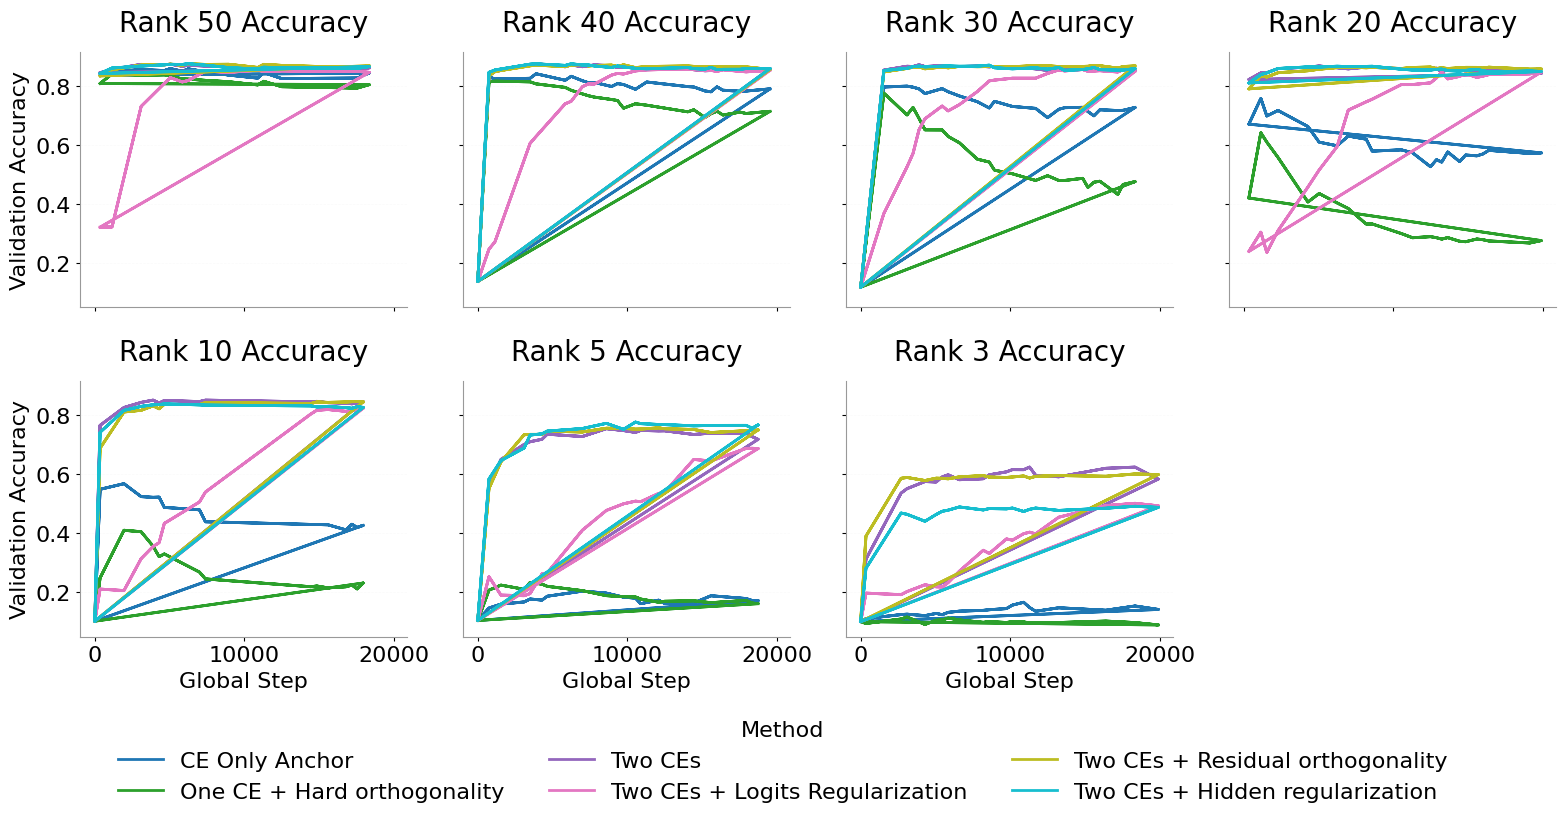

In [19]:
import pandas as pd
import numpy as np
import wandb
import matplotlib.pyplot as plt

# --- 1. Fetch training histories from wandb ---
api = wandb.Api()

runs_to_names = {
    'CE Only Anchor':                   ['for-paper-low-rank-teacher-only',                  'pauliusrauba/low-rank-performance/pwu2ynn4'],
    'One CE + Hard orthogonality':      ['for-paper-low-rank-hard-orthogonality',            'pauliusrauba/low-rank-performance/8gjuyn7e'],
    'Two CEs':                          ['for-paper-low-rank-ce-no-consistency',              'pauliusrauba/low-rank-performance/2ciim0l9'],
    'Two CEs + Logits Regularization':  ['for-paper-low-rank-ce-with-consistency',            'pauliusrauba/low-rank-performance/y0kespia'],
    'Two CEs + Residual orthogonality': ['for-paper-low-rank-ce-with-residual-orthogonality', 'pauliusrauba/low-rank-performance/enjfnffl'],
    'Two CEs + Hidden regularization':  ['for-paper-low-rank-ce-with-feature-consistency',    'pauliusrauba/low-rank-performance/czeuga4y'],
}

summary_dict = {}
for method_name, (run_name, run_path) in runs_to_names.items():
    run = api.run(run_path)
    summary_dict[run_name] = pd.DataFrame(run.scan_history())
    print(f"Fetched {run_name}: {summary_dict[run_name].shape}")

# --- 2. Plot OOD rank training dynamics ---
ood_ranks = [50, 40, 30, 20, 10, 5, 3]

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 18,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#666666',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

colors = {
    'text': 'black',
    'light_gray': '#E8E8E8',
    'med_gray': '#999999'
}

methods = list(runs_to_names.keys())
method_colors = plt.get_cmap('tab10', len(methods))

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
fig.patch.set_facecolor('white')
axes = axes.flatten()

for i, rank in enumerate(ood_ranks):
    ax = axes[i]
    for j, method_name in enumerate(methods):
        run_name = runs_to_names[method_name][0]
        history_df = summary_dict[run_name]
        history_df = history_df.loc[history_df['trainer/global_step'] <= 20_000]

        y_col = f'val/r{rank}_acc'
        x_col = 'trainer/global_step'

        if y_col in history_df.columns and x_col in history_df.columns:
            plot_df = history_df[[x_col, y_col]].dropna()
            ax.plot(plot_df[x_col], plot_df[y_col],
                    label=method_name,
                    color=method_colors(j),
                    linewidth=2)

    ax.set_title(f'Rank {rank} Accuracy', fontsize=20, color=colors['text'], fontweight='500', pad=15)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(0.8)
        ax.spines[spine].set_color(colors['med_gray'])

    ax.grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5,
            color=colors['light_gray'], zorder=1)
    ax.set_axisbelow(True)

    ax.tick_params(axis='both', which='major', labelsize=16, colors=colors['text'])
    ax.set_facecolor('white')

    if i % 4 == 0:
        ax.set_ylabel('Validation Accuracy', fontsize=16, color=colors['text'])
    if i >= 4:
        ax.set_xlabel('Global Step', fontsize=16, color=colors['text'])

# Hide the unused 8th subplot (2x4 grid, 7 OOD ranks)
axes[-1].axis('off')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.1),
           ncol=len(methods) // 2, fontsize=16, title='Method', title_fontsize=16)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#plt.savefig('../figures/ood_rank_training_dynamics.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 6. Accuracy vs rank trade-off for pre-trained LLMs

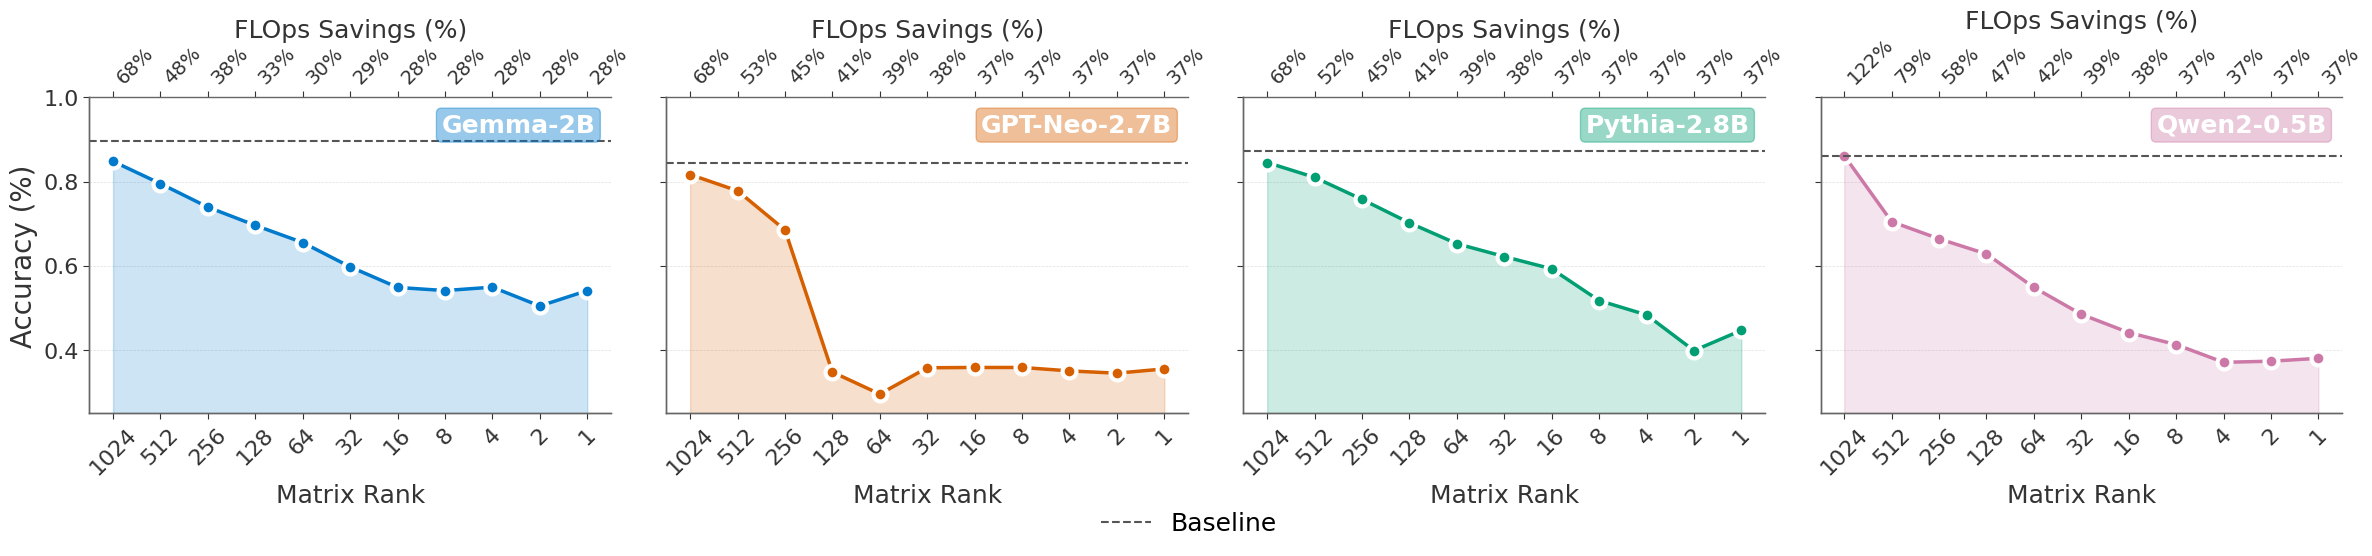

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Load exp_05 results
df = pd.read_csv('../results/exp_05/llm_performance.csv')

# ===============================================================
# Style and Color Preparation
# ===============================================================
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 14,
    'axes.linewidth': 1,
    'axes.edgecolor': '#666666',
    'axes.labelcolor': '#333333',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

plot_colors = ['#007ACC', '#D65F00', '#009E73', '#CC79A7']

model_display_names = {
    'EleutherAI/pythia-2.8b': 'Pythia-2.8B',
    'EleutherAI/gpt-neo-2.7B': 'GPT-Neo-2.7B',
    'Qwen/Qwen2-0.5B': 'Qwen2-0.5B',
    'google/gemma-2b': 'Gemma-2B'
}

# ===============================================================
# Plotting
# ===============================================================
model_names = df['model_name'].unique()

fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharey=True)
fig.patch.set_facecolor('white')

for i, model_name in enumerate(model_names):
    ax = axes[i]
    model_df = df[df['model_name'] == model_name]
    curriculum_df = model_df[model_df['training_type'] == 'epoch_curriculum'].sort_values('rank')
    
    base_rows = model_df[model_df['training_type'] == 'base']
    baseline_acc = base_rows['mismatched_accuracy'].iloc[0] if len(base_rows) > 0 else 0.0

    ax.plot(curriculum_df['rank'], curriculum_df['mismatched_accuracy'],
            color=plot_colors[i], linewidth=2.5, zorder=3)
    ax.plot(curriculum_df['rank'], curriculum_df['mismatched_accuracy'],
            marker='o', markersize=10, markerfacecolor=plot_colors[i],
            markeredgecolor='white', markeredgewidth=3,
            linestyle='None', zorder=4)
    ax.fill_between(curriculum_df['rank'], curriculum_df['mismatched_accuracy'],
                    color=plot_colors[i], alpha=0.2, zorder=2)

    max_rank_acc = curriculum_df.loc[curriculum_df['rank'] == curriculum_df['rank'].max(), 'mismatched_accuracy'].iloc[0]
    line_label = 'Baseline' if i == 0 else ""
    ax.axhline(y=max(baseline_acc, max_rank_acc), color='#555555', linestyle='--',
               linewidth=1.5, label=line_label, zorder=4)

    model_text = model_display_names.get(model_name, model_name)
    ax.text(0.97, 0.95, model_text,
            transform=ax.transAxes, fontsize=18, fontweight='bold',
            color='white', va='top', ha='right',
            bbox=dict(boxstyle='round,pad=0.2', facecolor=plot_colors[i],
                      edgecolor=plot_colors[i], alpha=0.4),
            zorder=5)

    ax.set_xlabel("Matrix Rank", fontsize=18)
    ax.set_xscale('log', base=2)
    ax.invert_xaxis()
    ax.set_xticks(curriculum_df['rank'].values)
    ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
    ax.set_ylim(0.25, 1.0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='x', rotation=45, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid(axis='y', alpha=0.4, linestyle='--', linewidth=0.5)

    ax2 = ax.twiny()
    param_percentages = curriculum_df['params_percentage_numeric']
    ax2.set_xscale('log', base=2)
    ax2.set_xlim(ax.get_xlim())
    tick_positions = curriculum_df['rank'].values
    tick_labels = [f'{p:.0f}%' for p in param_percentages]
    ax2.set_xticks(tick_positions)
    ax2.set_xticklabels(tick_labels, rotation=45, ha='left')
    ax2.set_xlabel('FLOps Savings (%)', fontsize=18)
    ax2.spines['right'].set_visible(False)
    ax.set_axisbelow(True)

axes[0].set_ylabel('Accuracy (%)', fontsize=20)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center',
           bbox_to_anchor=(0.5, 0), ncol=1, fontsize=18, frameon=False)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig('../results/exp_05/performance_across_llms_flops.pdf', bbox_inches='tight')
plt.show()

# 7. Energy decay assumption

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/388 [00:00<?, ?it/s]

You shouldn't move a model that is dispatched using accelerate hooks.


Loading weights:   0%|          | 0/387 [00:00<?, ?it/s]

GPTNeoXForSequenceClassification LOAD REPORT from: EleutherAI/pythia-2.8b
Key              | Status     | 
-----------------+------------+-
embed_out.weight | UNEXPECTED | 
score.weight     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
You shouldn't move a model that is dispatched using accelerate hooks.
You shouldn't move a model that is dispatched using accelerate hooks.


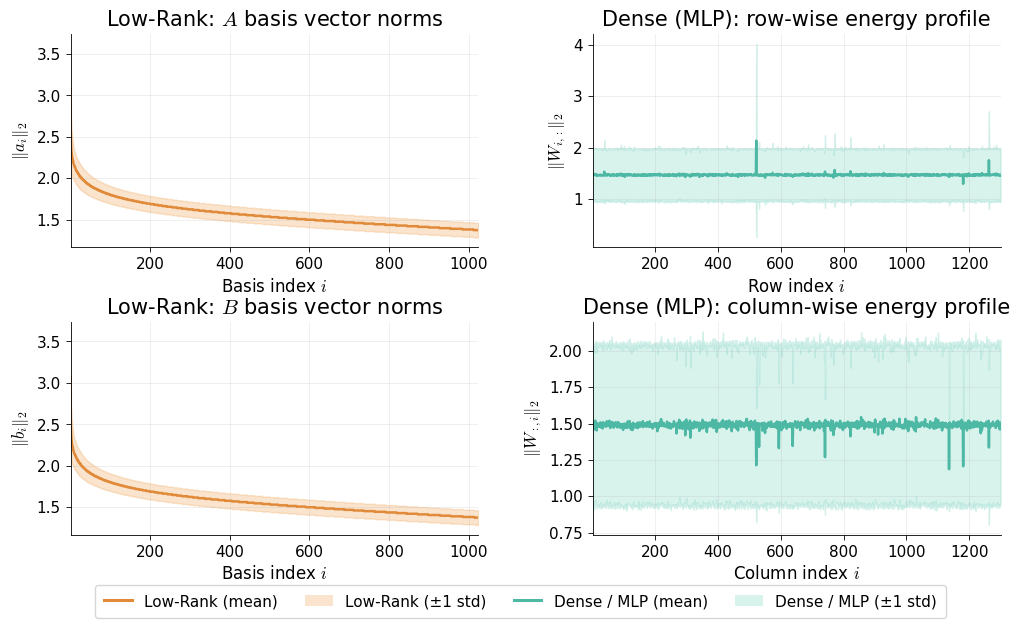

In [5]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib as mpl
from types import MethodType
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments
from safetensors.torch import load_file

# ========================
# 1. DynamicLowRankLinear
# ========================
class DynamicLowRankLinear(nn.Module):
    def __init__(self, in_features, out_features, max_rank, bias=True):
        super().__init__()
        self.max_rank = max_rank
        self.active_rank = max_rank
        self.A = nn.Linear(in_features, max_rank, bias=False)
        self.B = nn.Linear(max_rank, out_features, bias=bias)

    def set_rank(self, rank):
        self.active_rank = max(1, rank)

    def forward(self, x):
        r = self.active_rank
        A_weight = self.A.weight[:r, :]
        B_weight = self.B.weight[:, :r]
        return F.linear(F.linear(x, A_weight), B_weight, self.B.bias)


def decompose_and_replace(model, max_rank, target_substring="mlp"):
    for full_name, module in list(model.named_modules()):
        if target_substring in full_name and isinstance(module, nn.Linear):
            W = module.weight.data.to(torch.float32)
            U, S, Vh = torch.linalg.svd(W, full_matrices=False)
            r = min(max_rank, S.size(0))
            U, S, Vh = U[:, :r], S[:r], Vh[:r, :]
            S_sqrt = torch.sqrt(S)
            B_weight = U @ torch.diag(S_sqrt)
            A_weight = torch.diag(S_sqrt) @ Vh
            new_layer = DynamicLowRankLinear(
                module.in_features, module.out_features, max_rank, bias=(module.bias is not None)
            ).to(module.weight.device).to(module.weight.dtype)
            new_layer.A.weight.data = A_weight.to(new_layer.A.weight.dtype)
            new_layer.B.weight.data = B_weight.to(new_layer.B.weight.dtype)
            if module.bias is not None:
                new_layer.B.bias.data = module.bias.data.to(new_layer.B.bias.dtype)
            name_parts = full_name.split('.')
            parent_name = '.'.join(name_parts[:-1])
            local_name = name_parts[-1]
            parent_module = model.get_submodule(parent_name)
            setattr(parent_module, local_name, new_layer)
    return model


# ========================
# 2. Config
# ========================
base_model_id = 'EleutherAI/pythia-2.8b'
device = 'cuda:0'
data_dir = '/mnt/pdata/pr501/shortcut-models/dataset'
model_cache_dir = os.path.join(data_dir, 'huggingface_models')
model_checkpoint_dense = '/mnt/pdata/pr501/shortcut-models/checkpoints/pythia-base/final_model/'
model_checkpoint_lowrank = '/mnt/pdata/pr501/shortcut-models/checkpoints/pythia-epoch-curriculum/checkpoint-36816/'
max_rank = 1024

tokenizer = AutoTokenizer.from_pretrained(base_model_id, cache_dir=model_cache_dir)
tokenizer.pad_token = tokenizer.eos_token


# ========================
# 3. Load Dense Model
# ========================
model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint_dense, num_labels=3, pad_token_id=tokenizer.pad_token_id,
    torch_dtype=torch.bfloat16, cache_dir=model_cache_dir, device_map='auto',
).to(device)


# ========================
# 4. Load Low-Rank Model
# ========================
model2 = AutoModelForSequenceClassification.from_pretrained(
    base_model_id, num_labels=3, pad_token_id=tokenizer.pad_token_id,
    torch_dtype=torch.bfloat16, cache_dir=model_cache_dir, device_map='auto',
).to(device)
decompose_and_replace(model2.gpt_neox, max_rank=max_rank, target_substring='mlp')

model2.max_rank = max_rank
model2.train_ranks = [max_rank // (2**k) for k in range(int(math.log2(max_rank)) + 1) if max_rank // (2**k) > 0]
model2.log_vars_ce = nn.ParameterDict({str(r): nn.Parameter(torch.zeros(())) for r in model2.train_ranks}).to(model2.device)

def _set_rank_all_method(self, rank):
    for m in self.modules():
        if isinstance(m, DynamicLowRankLinear):
            m.set_rank(rank)

model2._set_rank_all = MethodType(_set_rank_all_method, model2)

weights_path = os.path.join(model_checkpoint_lowrank, 'model.safetensors')
state_dict = load_file(weights_path)
model2.load_state_dict(state_dict, strict=False)
model2 = model2.to(device)


# ========================
# 5. Helper Functions
# ========================
def get_rank1_component_norms(layer):
    with torch.no_grad():
        A = layer.A.weight
        B = layer.B.weight
        norms_a = torch.linalg.norm(A, dim=1)
        norms_b = torch.linalg.norm(B, dim=0)
    return norms_a.cpu(), norms_b.cpu()


def check_monotonic_nonincreasing(norms, atol=1e-6):
    diffs = norms[:-1] - norms[1:]
    violations_mask = diffs < -atol
    violation_indices = torch.nonzero(violations_mask, as_tuple=False).flatten().tolist()
    return (len(violation_indices) == 0), len(violation_indices), violation_indices, diffs


def collect_energy_decay_stats(mdl, atol=1e-6):
    dlr_layers = [(n, m) for n, m in mdl.named_modules() if isinstance(m, DynamicLowRankLinear)]
    layer_rows, all_norms_a, all_norms_b, layer_names = [], [], [], []
    max_R = 0
    for name, layer in dlr_layers:
        norms_a, norms_b = get_rank1_component_norms(layer)
        R = norms_a.shape[0]
        max_R = max(max_R, R)
        all_norms_a.append(norms_a); all_norms_b.append(norms_b); layer_names.append(name)
    def pad(t, L):
        return t if t.shape[0] == L else torch.cat([t, torch.full((L - t.shape[0],), float('nan'))])
    pa = torch.stack([pad(t, max_R) for t in all_norms_a], dim=0)
    pb = torch.stack([pad(t, max_R) for t in all_norms_b], dim=0)
    return None, {
        "max_R": max_R,
        "mean_norms_a": torch.nanmean(pa, dim=0), "mean_norms_b": torch.nanmean(pb, dim=0),
        "std_norms_a": torch.std(pa, dim=0), "std_norms_b": torch.std(pb, dim=0),
    }, all_norms_a, all_norms_b, layer_names


def collect_rowcol_energy_decay_stats(mdl, atol=1e-5):
    layers = [(n, m) for n, m in mdl.named_modules()
              if isinstance(m, torch.nn.Linear) and ("mlp.dense_h_to_4h" in n or "mlp.dense_4h_to_h" in n)]
    all_norms_a, all_norms_b, layer_names = [], [], []
    max_R = 0
    for name, layer in layers:
        W = layer.weight.data
        norms_a = torch.linalg.norm(W, dim=1).cpu()
        norms_b = torch.linalg.norm(W, dim=0).cpu()
        R = norms_a.shape[0]; C = norms_b.shape[0]
        max_R = max(max_R, max(R, C))
        all_norms_a.append(norms_a); all_norms_b.append(norms_b); layer_names.append(name)
    def pad(v, L):
        return v if len(v) == L else torch.cat([v, torch.full((L - len(v),), float('nan'))])
    pa = torch.stack([pad(v, max_R) for v in all_norms_a], dim=0)
    pb = torch.stack([pad(v, max_R) for v in all_norms_b], dim=0)
    return None, {
        "max_R": max_R,
        "mean_norms_a": torch.nanmean(pa, dim=0), "mean_norms_b": torch.nanmean(pb, dim=0),
        "std_norms_a": torch.std(pa, dim=0), "std_norms_b": torch.std(pb, dim=0),
    }, all_norms_a, all_norms_b, layer_names


# ========================
# 6. Compute Stats
# ========================
_, global_stats, _, _, _ = collect_energy_decay_stats(model2, atol=1e-5)
_, global_stats_dense, _, _, _ = collect_rowcol_energy_decay_stats(model, atol=1e-5)


# ========================
# 7. Plot the Figure
# ========================
CLR_LR    = "#e08a3a"
CLR_DENSE = "#4db8a4"
FILL_LR   = "#f0a85c"
FILL_DENSE = "#7fd4c2"

lr_mean_a = global_stats["mean_norms_a"].to(torch.float32).numpy()
lr_mean_b = global_stats["mean_norms_b"].to(torch.float32).numpy()
lr_std_a  = global_stats["std_norms_a"].to(torch.float32).numpy()
lr_std_b  = global_stats["std_norms_b"].to(torch.float32).numpy()
R_lr      = global_stats["max_R"]
idx_lr    = np.arange(1, R_lr + 1)

d_mean_a = global_stats_dense["mean_norms_a"].to(torch.float32).numpy()
d_mean_b = global_stats_dense["mean_norms_b"].to(torch.float32).numpy()
d_std_a  = global_stats_dense["std_norms_a"].to(torch.float32).numpy()
d_std_b  = global_stats_dense["std_norms_b"].to(torch.float32).numpy()
R_d      = 1300
idx_d    = np.arange(1, R_d + 1)
d_mean_a, d_std_a = d_mean_a[:R_d], d_std_a[:R_d]
d_mean_b, d_std_b = d_mean_b[:R_d], d_std_b[:R_d]

mpl.rcParams.update({
    "font.family": "sans-serif", "mathtext.fontset": "cm",
    "axes.titlesize": 15, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
})

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), gridspec_kw={"hspace": 0.35, "wspace": 0.28})

def style_ax(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["bottom"].set_linewidth(0.6)
    ax.tick_params(width=0.6)
    ax.grid(True, linewidth=0.4, alpha=0.35)

ax = axes[0, 0]
ax.plot(idx_lr, lr_mean_a, color=CLR_LR, linewidth=1.8)
ax.fill_between(idx_lr, lr_mean_a - lr_std_a, lr_mean_a + lr_std_a, color=FILL_LR, alpha=0.30)
ax.set_xlabel("Basis index $i$"); ax.set_ylabel(r"$\|a_i\|_2$")
ax.set_title("Low-Rank: $A$ basis vector norms"); ax.set_xlim(1, R_lr); style_ax(ax)

ax = axes[0, 1]
ax.plot(idx_d, d_mean_a, color=CLR_DENSE, linewidth=1.8)
ax.fill_between(idx_d, d_mean_a - d_std_a, d_mean_a + d_std_a, color=FILL_DENSE, alpha=0.30)
ax.set_xlabel("Row index $i$"); ax.set_ylabel(r"$\|W_{i,:}\|_2$")
ax.set_title("Dense (MLP): row-wise energy profile"); ax.set_xlim(1, R_d); style_ax(ax)

ax = axes[1, 0]
ax.plot(idx_lr, lr_mean_b, color=CLR_LR, linewidth=1.8)
ax.fill_between(idx_lr, lr_mean_b - lr_std_b, lr_mean_b + lr_std_b, color=FILL_LR, alpha=0.30)
ax.set_xlabel("Basis index $i$"); ax.set_ylabel(r"$\|b_i\|_2$")
ax.set_title("Low-Rank: $B$ basis vector norms"); ax.set_xlim(1, R_lr); style_ax(ax)

ax = axes[1, 1]
ax.plot(idx_d, d_mean_b, color=CLR_DENSE, linewidth=1.8)
ax.fill_between(idx_d, d_mean_b - d_std_b, d_mean_b + d_std_b, color=FILL_DENSE, alpha=0.30)
ax.set_xlabel("Column index $i$"); ax.set_ylabel(r"$\|W_{:,i}\|_2$")
ax.set_title("Dense (MLP): column-wise energy profile"); ax.set_xlim(1, R_d); style_ax(ax)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], color=CLR_LR, linewidth=2.2, label="Low-Rank (mean)"),
    Patch(facecolor=FILL_LR, alpha=0.30, label="Low-Rank (±1 std)"),
    Line2D([0], [0], color=CLR_DENSE, linewidth=2.2, label="Dense / MLP (mean)"),
    Patch(facecolor=FILL_DENSE, alpha=0.30, label="Dense / MLP (±1 std)"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4,
           frameon=True, fancybox=True, shadow=False, edgecolor="#cccccc",
           borderpad=0.6, columnspacing=1.8, handlelength=1.8,
           bbox_to_anchor=(0.5, -0.03))

#plt.savefig("energy_decay_2x2.pdf", dpi=200, bbox_inches="tight")
plt.show()

# 8. Violation of assumption - rates

In [8]:
import torch

def collect_rowcol_energy_decay_stats(model, atol=1e-5):
    """
    For a standard GPT-NeoX model with dense Linear MLP layers,
    compute:
       a_i = row i of W
       b_i = column i of W

    and evaluate monotonicity of ||a_i|| and ||b_i||.
    This matches the correct analogue of Assumption 1.
    """

    layers = []
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Linear) and (
            "mlp.dense_h_to_4h" in name or "mlp.dense_4h_to_h" in name
        ):
            layers.append((name, module))

    rows = []
    all_norms_a = []
    all_norms_b = []
    layer_names = []

    max_R = 0

    for name, layer in layers:
        W = layer.weight.data   # [d_out, d_in]

        norms_a = torch.linalg.norm(W, dim=1).cpu()  # row norms
        norms_b = torch.linalg.norm(W, dim=0).cpu()  # column norms

        R = norms_a.shape[0]   # row count (output units)
        C = norms_b.shape[0]   # col count (input units)

        max_R = max(max_R, max(R, C))

        # monotonicity checks
        def monotonic(v):
            diffs = v[:-1] - v[1:]
            viol = (diffs < -atol).nonzero(as_tuple=False).flatten().tolist()
            return (len(viol)==0), len(viol)

        A_mon, A_viol = monotonic(norms_a)
        B_mon, B_viol = monotonic(norms_b)

        pretty_name = name.replace("gpt_neox.layers.","L")
        pretty_name = pretty_name.replace(".mlp.dense_h_to_4h"," h→4h")
        pretty_name = pretty_name.replace(".mlp.dense_4h_to_h"," 4h→h")

        rows.append({
            "layer_name": pretty_name,
            "R_rows": R,
            "R_cols": C,
            "A_strict": A_mon,
            "A_viol": A_viol,
            "B_strict": B_mon,
            "B_viol": B_viol,
            "A_first": norms_a[0].item(),
            "A_last": norms_a[-1].item(),
            "B_first": norms_b[0].item(),
            "B_last": norms_b[-1].item(),
        })

        all_norms_a.append(norms_a)
        all_norms_b.append(norms_b)
        layer_names.append(pretty_name)

    # Construct global averages like before
    def pad(v, L):
        if len(v)==L:
            return v
        return torch.cat([v, torch.full((L-len(v),), float('nan'))])

    padded_a = torch.stack([pad(v, max_R) for v in all_norms_a], dim=0)
    padded_b = torch.stack([pad(v, max_R) for v in all_norms_b], dim=0)

    global_stats = {
        "max_R": max_R,
        "mean_norms_a": torch.nanmean(padded_a, dim=0),
        "mean_norms_b": torch.nanmean(padded_b, dim=0),
        "std_norms_a": torch.std(padded_a, dim=0),
        "std_norms_b": torch.std(padded_b, dim=0),
    }

    return rows, global_stats, all_norms_a, all_norms_b, layer_names



# ---------------------------------------------------------
rows_dense, global_stats_dense, all_norms_a_dense, all_norms_b_dense, layer_names_dense = (
    collect_rowcol_energy_decay_stats(model, atol=1e-5)
)

print(f"Analyzed {len(rows_dense)} MLP Linear layers.")
print("Example row:", rows_dense[0])
df_dense = pd.DataFrame(rows_dense)


Analyzed 64 MLP Linear layers.
Example row: {'layer_name': 'L0 h→4h', 'R_rows': 10240, 'R_cols': 2560, 'A_strict': False, 'A_viol': 5023, 'B_strict': False, 'B_viol': 1132, 'A_first': 0.984375, 'A_last': 0.8671875, 'B_first': 1.8359375, 'B_last': 1.8515625}


In [10]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import math

# ---------- 1. Helpers to compute norms and monotonicity ----------

def get_rank1_component_norms(layer):
    """
    For a DynamicLowRankLinear layer with factors A, B:
      A: [R, d_in]   (rows are a_i)
      B: [d_out, R]  (columns are b_i)
    Returns:
      norms_a: tensor [R] with ||a_i||_2
      norms_b: tensor [R] with ||b_i||_2
    """
    with torch.no_grad():
        A = layer.A.weight   # [R, d_in]
        B = layer.B.weight   # [d_out, R]
        norms_a = torch.linalg.norm(A, dim=1)  # row-wise
        norms_b = torch.linalg.norm(B, dim=0)  # column-wise
    return norms_a.cpu(), norms_b.cpu()


def check_monotonic_nonincreasing(norms: torch.Tensor, atol: float = 1e-6):
    """
    Check monotone non-increasing:
        norms[0] >= norms[1] >= ... (within tolerance atol)
    Returns:
      is_strict: bool
      num_violations: count of indices i where norms[i+1] > norms[i] + atol
      violation_indices: list of such i
      diffs: norms[:-1] - norms[1:]
    """
    diffs = norms[:-1] - norms[1:]
    violations_mask = diffs < -atol
    violation_indices = torch.nonzero(violations_mask, as_tuple=False).flatten().tolist()
    num_violations = len(violation_indices)
    is_strict = (num_violations == 0)
    return is_strict, num_violations, violation_indices, diffs


# ---------- 2. Extract per-layer stats from model2 ----------

def collect_energy_decay_stats(model, atol: float = 1e-6):
    dlr_layers = []
    for name, module in model.named_modules():
        if isinstance(module, DynamicLowRankLinear):
            dlr_layers.append((name, module))

    if not dlr_layers:
        raise RuntimeError("No DynamicLowRankLinear layers found in the model.")

    layer_rows = []
    all_norms_a = []
    all_norms_b = []
    layer_names = []

    max_R = 0

    for name, layer in dlr_layers:
        norms_a, norms_b = get_rank1_component_norms(layer)
        R = norms_a.shape[0]
        max_R = max(max_R, R)

        a_strict, a_nviol, a_idx, _ = check_monotonic_nonincreasing(norms_a, atol=atol)
        b_strict, b_nviol, b_idx, _ = check_monotonic_nonincreasing(norms_b, atol=atol)

        # Save per-layer stats
        row = {
            "layer_name": name,
            "rank_R": R,
            "A_strict_monotone": a_strict,
            "A_num_violations": a_nviol,
            "B_strict_monotone": b_strict,
            "B_num_violations": b_nviol,
            "A_mean_norm": norms_a.mean().item(),
            "B_mean_norm": norms_b.mean().item(),
            "A_first_norm": norms_a[0].item(),
            "B_first_norm": norms_b[0].item(),
            "A_last_norm": norms_a[-1].item(),
            "B_last_norm": norms_b[-1].item(),
        }
        layer_rows.append(row)

        all_norms_a.append(norms_a)
        all_norms_b.append(norms_b)
        layer_names.append(name)

    # Prepare padded tensors for global averages
    def pad_to_max(t, max_len):
        if t.shape[0] == max_len:
            return t
        pad_len = max_len - t.shape[0]
        return torch.cat([t, torch.full((pad_len,), float('nan'))])

    all_norms_a_padded = torch.stack([pad_to_max(t, max_R) for t in all_norms_a], dim=0)
    all_norms_b_padded = torch.stack([pad_to_max(t, max_R) for t in all_norms_b], dim=0)

    mean_norms_a = torch.nanmean(all_norms_a_padded, dim=0)
    mean_norms_b = torch.nanmean(all_norms_b_padded, dim=0)
    std_norms_a = torch.std(all_norms_a_padded, dim=0)
    std_norms_b = torch.std(all_norms_b_padded, dim=0)

    # Monotonicity of the *average* profile
    a_strict_global, a_nviol_global, _, _ = check_monotonic_nonincreasing(mean_norms_a, atol=atol)
    b_strict_global, b_nviol_global, _, _ = check_monotonic_nonincreasing(mean_norms_b, atol=atol)

    global_stats = {
        "max_R": max_R,
        "mean_norms_a": mean_norms_a,
        "mean_norms_b": mean_norms_b,
        "std_norms_a": std_norms_a,
        "std_norms_b": std_norms_b,
        "A_global_strict_monotone": a_strict_global,
        "A_global_num_violations": a_nviol_global,
        "B_global_strict_monotone": b_strict_global,
        "B_global_num_violations": b_nviol_global,
    }

    df_layers = pd.DataFrame(layer_rows)
    return df_layers, global_stats, all_norms_a, all_norms_b, layer_names


# Run collection
df_layers, global_stats, all_norms_a, all_norms_b, layer_names = collect_energy_decay_stats(
    model2, atol=1e-5
)

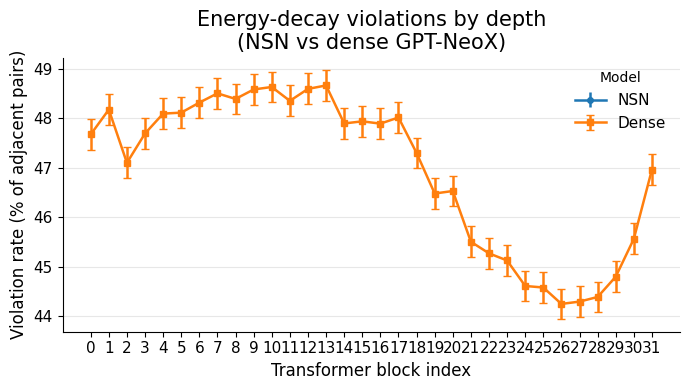

In [11]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Helper ----
def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"None of {candidates} found.")

# ---- Build df_dense from rows_dense (if not already a DataFrame) ----
df_dense = pd.DataFrame(rows_dense)

# ---- Extract block indices ----
def extract_block_id(name):
    m = re.match(r"L(\d+)", str(name))
    return int(m.group(1)) if m else None

df_layers["block_id"] = df_layers["layer_name"].apply(extract_block_id)
df_dense["block_id"]  = df_dense["layer_name"].apply(extract_block_id)

df_layers = df_layers.dropna(subset=["block_id"])
df_dense  = df_dense.dropna(subset=["block_id"])
df_layers["block_id"] = df_layers["block_id"].astype(int)
df_dense["block_id"]  = df_dense["block_id"].astype(int)

# ---- Per-block aggregation: NSN ----
A_viol_nsn = pick_col(df_layers, ["A_num_violations", "A_viol"])
B_viol_nsn = pick_col(df_layers, ["B_num_violations", "B_viol"])

records = []
for block_id, sub in df_layers.groupby("block_id"):
    pairs = 2 * (sub["rank_R"] - 1).sum()
    viol  = sub[A_viol_nsn].sum() + sub[B_viol_nsn].sum()
    p  = viol / pairs if pairs > 0 else np.nan
    se = np.sqrt(p * (1 - p) / pairs) if pairs > 0 else np.nan
    records.append(dict(block_id=block_id, model_type="NSN", pairs=pairs,
                        violations=viol, rate=p, se=se))
df_nsn_block = pd.DataFrame(records)

# ---- Per-block aggregation: Dense ----
A_viol_dense = pick_col(df_dense, ["A_num_violations", "A_viol"])
B_viol_dense = pick_col(df_dense, ["B_num_violations", "B_viol"])

records = []
for block_id, sub in df_dense.groupby("block_id"):
    pairs = (sub["R_rows"] - 1).sum() + (sub["R_cols"] - 1).sum()
    viol  = sub[A_viol_dense].sum() + sub[B_viol_dense].sum()
    p  = viol / pairs if pairs > 0 else np.nan
    se = np.sqrt(p * (1 - p) / pairs) if pairs > 0 else np.nan
    records.append(dict(block_id=block_id, model_type="Dense", pairs=pairs,
                        violations=viol, rate=p, se=se))
df_dense_block = pd.DataFrame(records)

# ---- Combine & Plot ----
df_plot = pd.concat([df_nsn_block, df_dense_block], ignore_index=True)
df_plot = df_plot.sort_values(["model_type", "block_id"])

plt.figure(figsize=(7, 4))
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, axis="y", alpha=0.3)

for model_type, marker in [("NSN", "o"), ("Dense", "s")]:
    sub = df_plot[df_plot["model_type"] == model_type].sort_values("block_id")
    x    = sub["block_id"].to_numpy()
    y    = (sub["rate"] * 100.0).to_numpy()
    yerr = (sub["se"]   * 100.0).to_numpy()
    ax.errorbar(x, y, yerr=yerr, fmt=f"-{marker}", capsize=3,
                linewidth=1.8, markersize=4, label=model_type)

ax.set_xlabel("Transformer block index")
ax.set_ylabel("Violation rate (% of adjacent pairs)")
ax.set_title("Energy-decay violations by depth\n(NSN vs dense GPT-NeoX)")
ax.set_xticks(sorted(df_plot["block_id"].unique()))
ax.legend(title="Model", frameon=False)
plt.tight_layout()
#plt.savefig("violation_rate_by_block_nsn_vs_dense.pdf", dpi=150)
plt.show()

# 9. Low-rank convergence to standard solution

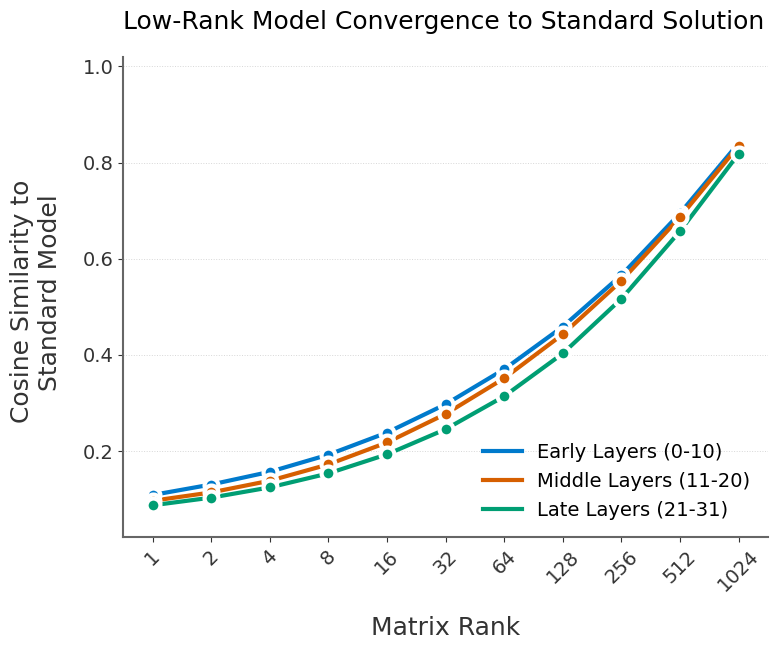

In [12]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import defaultdict

model_standard = model
model_lowrank   = model2

RANKS_TO_ANALYZE = sorted([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024])

def calculate_cosine_similarity(t1, t2):
    t1_flat = t1.flatten().to(torch.float32)
    t2_flat = t2.flatten().to(torch.float32)
    return torch.nn.functional.cosine_similarity(t1_flat, t2_flat, dim=0).item()

model_standard.eval(); model_lowrank.eval()
results = defaultdict(list)
num_layers = len(model_standard.gpt_neox.layers)

for i in range(num_layers):
    for layer_name in ["dense_h_to_4h", "dense_4h_to_h"]:
        W_standard = model_standard.gpt_neox.layers[i].mlp.get_submodule(layer_name).weight.data
        lr_layer   = model_lowrank.gpt_neox.layers[i].mlp.get_submodule(layer_name)
        A_w, B_w   = lr_layer.A.weight.data, lr_layer.B.weight.data
        for rank in RANKS_TO_ANALYZE:
            with torch.no_grad():
                W_lr = B_w[:, :rank] @ A_w[:rank, :]
                sim  = calculate_cosine_similarity(W_standard, W_lr)
            results["layer_idx"].append(i)
            results["layer_name"].append(layer_name)
            results["rank"].append(rank)
            results["similarity"].append(sim)

results_df = pd.DataFrame(results)

# ---- Plotting ----
df_agg = results_df.groupby(['layer_idx', 'rank'])['similarity'].mean().reset_index()

def get_layer_group(idx):
    if idx < 11:  return "Early Layers (0-10)"
    elif idx < 21: return "Middle Layers (11-20)"
    else:          return "Late Layers (21-31)"

df_agg['layer_group'] = df_agg['layer_idx'].apply(get_layer_group)

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 14, 'axes.linewidth': 1.5, 'axes.edgecolor': '#666666',
    'axes.labelcolor': '#333333', 'xtick.color': '#333333', 'ytick.color': '#333333',
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42
})

color_palette = {
    "Early Layers (0-10)": "#007ACC",
    "Middle Layers (11-20)": "#D65F00",
    "Late Layers (21-31)": "#009E73"
}

fig, ax = plt.subplots(figsize=(8, 7))
fig.patch.set_facecolor('white')

for group_name in ["Early Layers (0-10)", "Middle Layers (11-20)", "Late Layers (21-31)"]:
    gdf   = df_agg[df_agg['layer_group'] == group_name]
    mean  = gdf.groupby('rank')['similarity'].mean().reset_index()
    color = color_palette[group_name]
    ax.plot(mean['rank'], mean['similarity'], color=color, linewidth=3, label=group_name, zorder=3)
    ax.plot(mean['rank'], mean['similarity'], marker='o', markersize=10,
            markerfacecolor=color, markeredgecolor='white', markeredgewidth=3,
            linestyle='None', zorder=4)

ax.set_title('Low-Rank Model Convergence to Standard Solution', fontsize=18, pad=20, loc='left')
ax.set_xlabel("Matrix Rank", fontsize=18, labelpad=15)
ax.set_ylabel('Cosine Similarity to \n Standard Model', fontsize=18, labelpad=15)
ax.set_xscale('log', base=2)
ax.set_xticks(RANKS_TO_ANALYZE)
ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
ax.tick_params(axis='x', rotation=45, labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_ylim(max(0, df_agg['similarity'].min() - 0.05), 1.02)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.5, linestyle=':', linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(loc='lower right', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('low_rank_convergence.pdf', bbox_inches='tight')
plt.show()

# 10. Subspace Containment Heatmap

In [ ]:
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict

model_lowrank = model2
model_lowrank.eval()

RANKS_TO_ANALYZE = sorted(model_lowrank.train_ranks)
containment_results = defaultdict(list)
num_layers = len(model_lowrank.gpt_neox.layers)

for i in range(num_layers):
    for layer_name in ["dense_h_to_4h", "dense_4h_to_h"]:
        lr_layer = model_lowrank.gpt_neox.layers[i].mlp.get_submodule(layer_name)
        A_w, B_w = lr_layer.A.weight.data, lr_layer.B.weight.data

        bases = {}
        with torch.no_grad():
            for rank in RANKS_TO_ANALYZE:
                W_r = B_w[:, :rank] @ A_w[:rank, :]
                U, _, _ = torch.linalg.svd(W_r.float(), full_matrices=False)
                bases[rank] = U[:, :rank]

        for r_large in RANKS_TO_ANALYZE:
            for r_small in RANKS_TO_ANALYZE:
                U_large, U_small = bases[r_large], bases[r_small]
                with torch.no_grad():
                    proj_norm_sq = torch.norm(U_large.T @ U_small, p='fro')**2
                    score = (proj_norm_sq / r_small).item()
                containment_results["layer_idx"].append(i)
                containment_results["layer_name"].append(layer_name)
                containment_results["r_large"].append(r_large)
                containment_results["r_small"].append(r_small)
                containment_results["containment_score"].append(score)

results_df = pd.DataFrame(containment_results)

# ---- Heatmap Plotting ----
summary_df   = results_df.groupby(['r_large', 'r_small'])['containment_score'].mean().reset_index()
heatmap_pivot = summary_df.pivot(index="r_small", columns="r_large", values="containment_score")

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 14, 'axes.linewidth': 1.5, 'axes.labelcolor': '#333333',
    'pdf.fonttype': 42, 'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(12, 10))
fig.patch.set_facecolor('white')

cmap = sns.light_palette("#007ACC", as_cmap=True)
sns.heatmap(heatmap_pivot, annot=True, fmt=".3f", cmap=cmap,
            linewidths=5, linecolor='white', ax=ax, annot_kws={"size": 12},
            cbar_kws={'label': 'Containment Score', "shrink": 0.75})

ax.set_title(
    r'How much is each weight $W_{r_{small}}$ matrix contained in another $W_{r_{large}}$ matrix?',
    loc='left', fontsize=14, pad=20)
ax.set_xlabel(r"Larger Rank ($r_{large}$)", fontsize=18, labelpad=15)
ax.set_ylabel(r"Smaller Rank ($r_{small}$)", fontsize=18, labelpad=15)
ax.tick_params(axis='x', labelsize=14, rotation=0)
ax.tick_params(axis='y', labelsize=14, rotation=0)

note = "Note: Average score across all MLP layers. Score of 1.0 = low-rank space fully contained in larger one."
fig.text(0.5, 0.01, note, ha='center', va='bottom', fontsize=12, color='#555555')

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig('subspace_containment_heatmap.pdf', bbox_inches='tight')
plt.show()

# 11. Inner-Layer weight similarity vs matrix rank.

In [ ]:
import torch
import itertools
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

model_lowrank = model2
model_lowrank.eval()

try:
    ranks_to_analyze = sorted(model_lowrank.train_ranks)
except AttributeError:
    ranks_to_analyze = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]

layers_to_compare = range(22)
mlp_layers = {i: model_lowrank.gpt_neox.layers[i].mlp.dense_h_to_4h for i in layers_to_compare}

def calculate_cosine_similarity(t1, t2):
    t1f = t1.flatten().to(torch.float32)
    t2f = t2.flatten().to(torch.float32)
    return torch.nn.functional.cosine_similarity(t1f, t2f, dim=0).item()

results_list = []
for rank in ranks_to_analyze:
    reconstructed = {}
    with torch.no_grad():
        for i, mlp_layer in mlp_layers.items():
            r = min(rank, mlp_layer.max_rank)
            A_w = mlp_layer.A.weight.data[:r, :]
            B_w = mlp_layer.B.weight.data[:, :r]
            reconstructed[i] = B_w @ A_w

        for i, j in itertools.combinations(layers_to_compare, 2):
            sim = calculate_cosine_similarity(reconstructed[i], reconstructed[j])
            results_list.append(dict(rank=rank, layer_1=i, layer_2=j, cosine_similarity=sim))

inter_layer_weight_similarity_df = pd.DataFrame(results_list)

# ---- Plotting ----
average_similarity_df = inter_layer_weight_similarity_df.groupby('rank')['cosine_similarity'].mean().reset_index()
inter_layer_weight_similarity_df['layer_pair'] = (
    'L' + inter_layer_weight_similarity_df['layer_1'].astype(str) +
    '-L' + inter_layer_weight_similarity_df['layer_2'].astype(str))

plt.style.use('default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 14, 'axes.linewidth': 1.5, 'axes.edgecolor': '#666666',
    'axes.labelcolor': '#333333', 'legend.frameon': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor('white')

lowest_rank = ranks_to_analyze[0]
df_lr = inter_layer_weight_similarity_df[inter_layer_weight_similarity_df['rank'] == lowest_rank]
high_pair_str = df_lr.loc[df_lr['cosine_similarity'].idxmax(), 'layer_pair']
low_pair_str  = df_lr.loc[df_lr['cosine_similarity'].idxmin(), 'layer_pair']
point_high = df_lr.loc[df_lr['cosine_similarity'].idxmax()]
point_low  = df_lr.loc[df_lr['cosine_similarity'].idxmin()]

df_bg = inter_layer_weight_similarity_df[
    ~inter_layer_weight_similarity_df['layer_pair'].isin([high_pair_str, low_pair_str])]
df_hi = inter_layer_weight_similarity_df[inter_layer_weight_similarity_df['layer_pair'] == high_pair_str]
df_lo = inter_layer_weight_similarity_df[inter_layer_weight_similarity_df['layer_pair'] == low_pair_str]

sns.lineplot(data=df_bg, x='rank', y='cosine_similarity', hue='layer_pair',
             palette=['#E0E0E0'] * len(df_bg['layer_pair'].unique()),
             linewidth=0.8, alpha=0.6, legend=False, ax=ax, zorder=1)

highlight = '#CC79A7'
ax.plot(df_hi['rank'], df_hi['cosine_similarity'], color=highlight, linewidth=1.5, zorder=2)
ax.plot(df_lo['rank'], df_lo['cosine_similarity'], color=highlight, linewidth=1.5, zorder=2)

avg_color = '#007ACC'
ax.plot(average_similarity_df['rank'], average_similarity_df['cosine_similarity'],
        color=avg_color, linewidth=3, zorder=3, label='Average Similarity')
ax.plot(average_similarity_df['rank'], average_similarity_df['cosine_similarity'],
        marker='o', markersize=12, markerfacecolor=avg_color,
        markeredgecolor='white', markeredgewidth=3, linestyle='None', zorder=4)

ax.set_title('Inter-Layer Weight Similarity vs. Matrix Rank', fontsize=22, pad=20, loc='left')
ax.set_xlabel("Matrix Rank", fontsize=18, labelpad=15)
ax.set_ylabel('Cosine Similarity', fontsize=18, labelpad=15)
ax.set_xscale('log', base=2)
ax.set_xticks(ranks_to_analyze)
ax.get_xaxis().set_major_formatter(mticker.ScalarFormatter())
ax.tick_params(axis='x', rotation=45, labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_ylim(-0.1, 1.0)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.5, linestyle=':', linewidth=0.7)
ax.set_axisbelow(True)

x_h, y_h = point_high['rank'], point_high['cosine_similarity']
x_l, y_l = point_low['rank'],  point_low['cosine_similarity']

ax.annotate(f"Highest similarity at low rank",
    xy=(x_h, y_h), xytext=(lowest_rank * 16, 0.85), textcoords='data',
    ha='center', va='center', fontsize=12, color='#333333',
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.3',
                    color='#555555', linewidth=0.5, shrinkA=5, shrinkB=10),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#cccccc', alpha=0),
    zorder=10)

ax.annotate(f"Lowest similarity at low rank",
    xy=(x_l, y_l), xytext=(lowest_rank * 20, 0.5), textcoords='data',
    ha='center', va='center', fontsize=12, color='#333333',
    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=-0.3',
                    color='#555555', linewidth=0.5, shrinkA=5, shrinkB=10),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#cccccc', alpha=0),
    zorder=10)

ax.legend(loc='upper right', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('inter_layer_similarity.pdf', bbox_inches='tight')
plt.show()